<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

(2000, 10)


,battery_power,ram,int_memory,mobile_wt,n_cores,px_height,px_width,fc,pc,price_range
0,1626,1529,35,158,1,513,1589,10,12,1
1,1959,3444,46,91,8,349,1602,6,13,3
2,1360,3169,23,119,3,1932,1097,3,9,3
3,1794,1791,54,197,7,680,1725,19,10,2
4,1630,2881,60,99,7,1487,1057,6,12,3


Accuracy: 0.745
              precision    recall  f1-score   support

           0       0.84      0.89      0.86       100
           1       0.70      0.62      0.66       100
           2       0.63      0.60      0.62       100
           3       0.79      0.87      0.83       100

    accuracy                           0.74       400
   macro avg       0.74      0.74      0.74       400
weighted avg       0.74      0.74      0.74       400



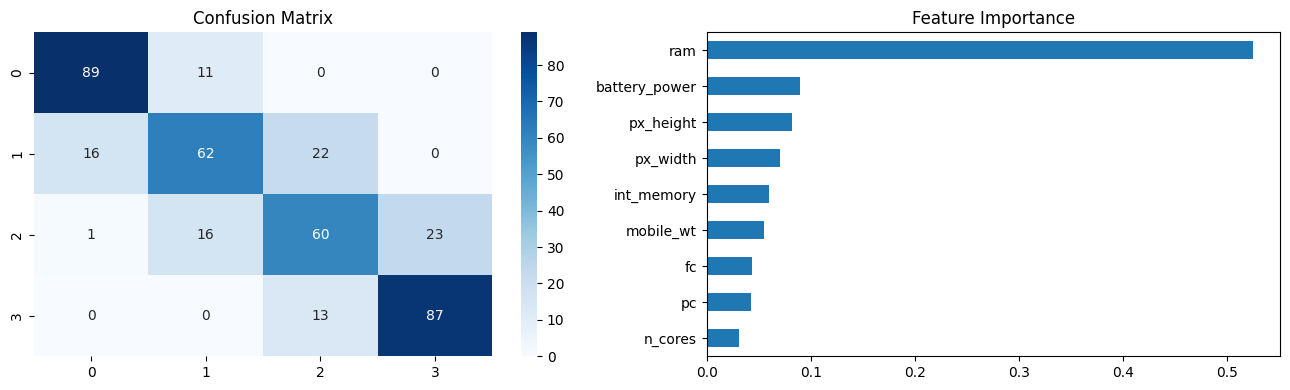

Predicted price range for a sample phone: 3 (0=low ... 3=very high)


In [3]:
if os.path.exists('train.csv'):
    df = pd.read_csv('train.csv')
else:
    n = 2000
    df = pd.DataFrame({
        'battery_power': np.random.randint(500, 2000, n),
        'ram': np.random.randint(256, 4000, n),
        'int_memory': np.random.randint(2, 64, n),
        'mobile_wt': np.random.randint(80, 200, n),
        'n_cores': np.random.randint(1, 9, n),
        'px_height': np.random.randint(0, 1960, n),
        'px_width': np.random.randint(500, 1998, n),
        'fc': np.random.randint(0, 20, n),
        'pc': np.random.randint(0, 20, n)})
    score = (0.6*df.ram/4000 + 0.15*df.battery_power/2000 + 0.1*df.px_height/1960
             + 0.1*df.px_width/2000 + 0.05*df.int_memory/64 + np.random.normal(0, 0.05, n))
    df['price_range'] = pd.qcut(score, 4, labels=[0,1,2,3]).astype(int)

print(df.shape); display(df.head())

X, y = df.drop('price_range', axis=1), df['price_range']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_tr, y_tr)
pred = model.predict(X_te)

print('Accuracy:', round(accuracy_score(y_te, pred), 4))
print(classification_report(y_te, pred))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(confusion_matrix(y_te, pred), annot=True, fmt='d', cmap='Blues', ax=ax[0])
ax[0].set_title('Confusion Matrix')
pd.Series(model.feature_importances_, X.columns).sort_values().plot.barh(ax=ax[1], title='Feature Importance')
plt.tight_layout(); plt.show()

print('Predicted price range for a sample phone:', model.predict(X_te.iloc[[0]])[0], '(0=low ... 3=very high)')

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             mean_squared_error, r2_score, mean_absolute_error)
np.random.seed(42)